In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [3]:
# calculating the efficient frontier
assets = ['AAPL','MSFT']
data = yf.download(assets,start='2010-01-01', auto_adjust=True)
data = data['Close']

c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_

In [4]:
assets_return = data / data.iloc[0] * 100
assets_return

apple_multiple = assets_return['AAPL']['2026-11-17'] / assets_return['AAPL']['2010-01-04']
microsoft_multiple = assets_return['MSFT']['2026-11-17'] / assets_return['MSFT']['2010-01-04']
print(f"AAPL has a {round(apple_multiple,3)}x and MSFT has a {round(microsoft_multiple,3)}x")

AAPL has a 55.019x and MSFT has a 22.026x


<Axes: xlabel='Date'>

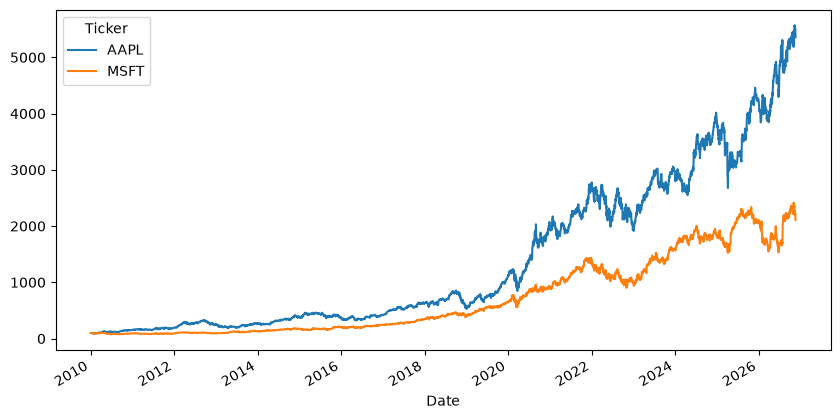

In [5]:
(assets_return).plot(figsize=(10,5))
#returns of apple and microsoft if you invested 100 dollars
#from 2010-01-01 to present day

In [6]:
#we need the log return (in general, it is whats used in the equations)

log_returns = np.log(data / data.shift(1))
log_returns.mean() * 250 #annualized log return

Ticker
AAPL    0.234328
MSFT    0.179555
dtype: float64

In [7]:
log_returns.cov() * 250

Ticker,AAPL,MSFT
Ticker,,
AAPL,0.078062,0.040039
MSFT,0.040039,0.067439


In [8]:
log_returns.corr() #fairly correlated (over 30% for sure)

Ticker,AAPL,MSFT
Ticker,,
AAPL,1.000000,0.551835
MSFT,0.551835,1.000000


In [9]:
num_assets = len(assets)
num_assets

2

In [10]:
#now need random weights
arr = np.random.random(2) #creates 2 random weights for us
arr

array([0.2711322 , 0.73225693])

In [11]:
arr[0] + arr[1] 

np.float64(1.0033891311124628)

In [12]:
#/= is the same as += or *= but for division
weights = np.random.random(num_assets)#2
weights /= np.sum(weights)
weights
#picks 2 random numbers, sums them up, and then divides each weight by the sum of the weights
#this fills an array with all the weights (whether it is 2 or 100 weights)


array([0.36822847, 0.63177153])

In [13]:
weights[0] + weights[1]

np.float64(0.9999999999999999)

In [14]:
#expected return
np.sum(weights * log_returns.mean() * 250)
#expected annual return for this portfolio given these weights is 18.9%


np.float64(0.1997238283604707)

In [15]:
#expected portfolio variance
np.dot(weights.T,np.dot(log_returns.cov() * 250 ,weights))

np.float64(0.05613119819152446)

In [16]:
#std (volatality)
np.sqrt(np.dot(weights.T,np.dot(log_returns.cov() * 250 ,weights)))

np.float64(0.23692023592661826)

In [17]:
#creating a graph of 1000 mean variance simulations

In [18]:
#need 2 empty lists
#1. for returns
#2. for volatility
port_returns = []
port_vol = []

for x in range (1000):
    weights = np.random.random(num_assets)
    weights /= np.sum(weights)
    port_returns.append(np.sum(weights * log_returns.mean() * 250))
    port_vol.append(np.sqrt(np.dot(weights.T,np.dot(log_returns.cov() * 250 ,weights))))

port_returns,port_vol

#looping through 1000 different times, we randomly generate 2 weights whose sum equals 1
#then we append each return into the return list and each vol into vol list (given the loops weights)


([np.float64(0.20330358702926557),
  np.float64(0.1907838888046413),
  np.float64(0.19958340937638858),
  np.float64(0.17982424495778518),
  np.float64(0.2015093679053483),
  np.float64(0.22114421924292227),
  np.float64(0.23325023308676804),
  np.float64(0.2089184576301139),
  np.float64(0.19900064440511517),
  np.float64(0.2055094496111341),
  np.float64(0.1995624500157307),
  np.float64(0.19578943612222072),
  np.float64(0.18933243498764327),
  np.float64(0.23058842348774997),
  np.float64(0.20219560517816965),
  np.float64(0.20703490300401017),
  np.float64(0.19924279710414516),
  np.float64(0.2059726569809689),
  np.float64(0.18591427594147614),
  np.float64(0.21153304017784402),
  np.float64(0.19069716378025636),
  np.float64(0.19317010289410586),
  np.float64(0.18819781323552962),
  np.float64(0.2215540653198972),
  np.float64(0.20544451531188818),
  np.float64(0.21059529375536779),
  np.float64(0.22256168930626724),
  np.float64(0.2022548634112264),
  np.float64(0.2043483148907

In [19]:
#these are hard to read so we need a way to put them into an array
port_returns = np.array(port_returns)
port_vol = np.array(port_vol)

port_returns,port_vol #each array has the return that has a corresponding vol in the other array

(array([0.20330359, 0.19078389, 0.19958341, 0.17982424, 0.20150937,
        0.22114422, 0.23325023, 0.20891846, 0.19900064, 0.20550945,
        0.19956245, 0.19578944, 0.18933243, 0.23058842, 0.20219561,
        0.2070349 , 0.1992428 , 0.20597266, 0.18591428, 0.21153304,
        0.19069716, 0.1931701 , 0.18819781, 0.22155407, 0.20544452,
        0.21059529, 0.22256169, 0.20225486, 0.20434831, 0.21824937,
        0.18194631, 0.19923962, 0.20245828, 0.19332124, 0.20886961,
        0.21223249, 0.19825131, 0.18186997, 0.21308238, 0.20164528,
        0.2148058 , 0.19651728, 0.18083675, 0.23350774, 0.19244854,
        0.1808461 , 0.22589117, 0.21718928, 0.20160849, 0.20589368,
        0.20200202, 0.22322688, 0.21408004, 0.21255619, 0.20861921,
        0.22586994, 0.20924579, 0.18140957, 0.21116644, 0.21299857,
        0.19301688, 0.21729183, 0.205307  , 0.17995245, 0.22107977,
        0.20894492, 0.19920771, 0.21298049, 0.20230085, 0.20688952,
        0.19489658, 0.20456444, 0.22195431, 0.18

In [20]:
portfolio = pd.DataFrame({'Return':port_returns, 'Volatility':port_vol})
portfolio.head() #first 5 pairs of return and volatility

,Return,Volatility
0,0.203304,0.236597
1,0.190784,0.242805
2,0.199583,0.236957
3,0.179824,0.259175
4,0.201509,0.236611


Text(0, 0.5, 'Expected Return')

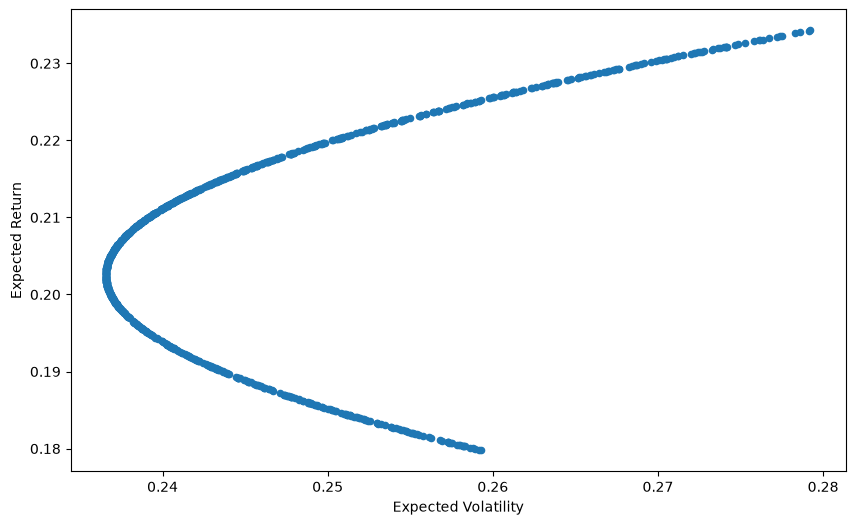

In [21]:
#now to plot
portfolio.plot(x='Volatility', y='Return', kind='scatter',figsize=(10,6))
#kind allows us to plot the type of plot we want
#plots a perfect markowitz curve
plt.xlabel('Expected Volatility')
plt.ylabel('Expected Return')


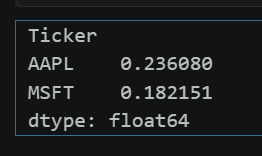

We can see here that Apple's 100% (Asset A) is the top right tip

Whereas Microsfofts 100% (Asset B) is the very bottom (to middle right ish) tip

In [ ]:
#minimum variance portfolio
min_var_idx = portfolio['Volatility'].idxmin()
#idxmin() gives us the location of the lowest value
min_var_port = portfolio.loc[min_var_idx]
min_var_port

Return        0.202469
Volatility    0.236567
Name: 649, dtype: float64

In [23]:
print(f"The Minimum Variance Portfolio is a volatility of {round(min_var_port['Volatility'],4) * 100}% with a expected annual return of {round(min_var_port['Return'],4) * 100}%")

The Minimum Variance Portfolio is a volatility of 23.66% with a expected annual return of 20.25%


In [24]:
#questions going forward to work on
#sharpe ratio? (Max sharpe)
#Optimal portfolio?
#Frontier?

## Capital Assset Pricing Model

Beta


In [32]:
ticker_with_market = ['AAPL','^GSPC']
port_with_market = yf.download(ticker_with_market,start='2010-01-01',auto_adjust=True)
port_with_market = port_with_market['Close']



c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
c:\Users\vince\Portfolio_project\.ven

In [36]:
PWM_log_returns = np.log(port_with_market / port_with_market.shift(1))
print(PWM_log_returns)
covariance = PWM_log_returns.cov() * 250
covariance

Ticker          AAPL     ^GSPC
Date                          
2010-01-04       NaN       NaN
2010-01-05  0.001728  0.003111
2010-01-06 -0.016034  0.000545
2010-01-07 -0.001850  0.003993
2010-01-08  0.006626  0.002878
...              ...       ...
2026-11-16 -0.009844 -0.019373
2026-11-17 -0.002469 -0.010308
2026-11-18  0.001533 -0.002305
2026-11-19 -0.009235 -0.020388
2026-11-20 -0.019227 -0.037692

[4248 rows x 2 columns]


Ticker,AAPL,^GSPC
Ticker,,
AAPL,0.078062,0.032408
^GSPC,0.032408,0.029493


In [ ]:
#Covariance with market (for the numerator)
cov_with_market = covariance.iloc[0,1] #selects 1st row and 2nd column
cov_with_market #selects the covariance of apple and the snp (market proxy)

np.float64(0.04003927092128768)

In [39]:
market_var = PWM_log_returns['^GSPC'].var() * 250
#annualized market variance
market_var #can check it is correct by looking at cov matrix above

np.float64(0.02949308051841875)

In [ ]:
Beta = cov_with_market / market_var 
# Beta = Cov(R_AAPL,R_M) / Var(R_M)
Beta #shows apple is an agressive stock
#our beta is much higher than the actual because we use daily returns
#daily returns captures short term noise
#Most institutional models use weekly or monthly intervals

np.float64(1.357581853692181)

Even though I used log returns, using simple returns might be more valuable here for CAPM

In [43]:
simple_returns = port_with_market.pct_change()
simple_returns

Ticker,AAPL,^GSPC
Date,,
2010-01-04,NaN,NaN
2010-01-05,0.001729,0.003116
2010-01-06,-0.015906,0.000546
2010-01-07,-0.001849,0.004001
2010-01-08,0.006648,0.002882
...,...,...
2026-11-16,-0.009796,-0.019186
2026-11-17,-0.002466,-0.010255
2026-11-18,0.001535,-0.002302


In [45]:
SR_cov = simple_returns.cov() * 250
SR_cov

Ticker,AAPL,^GSPC
Ticker,,
AAPL,0.078104,0.032342
^GSPC,0.032342,0.029352


In [46]:
SR_cov_with_market = SR_cov.iloc[0,1]
SR_cov_with_market

np.float64(0.03234225791363626)

In [47]:
SR_market_var = simple_returns['^GSPC'].var() * 250
SR_market_var

np.float64(0.029352088351539966)

In [49]:
SR_beta = SR_cov_with_market / SR_market_var
SR_beta #much closer to actual AAPL beta

np.float64(1.1018724639379678)

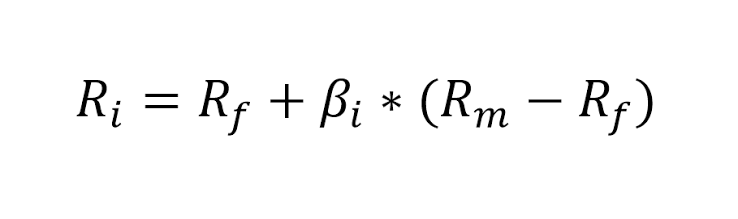

Rf = risk free rate

Bi = Beta between stock and market

Rm = market return

Ri = expected return of the stock


In [56]:
rfr_proxy = yf.download('^TNX',period="5d",auto_adjust=True)
rfr_proxy = rfr_proxy['Close']
rfr_proxy

c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
[*********************100%***********

Ticker,^TNX
Date,
2026-11-16,5.121
2026-11-17,5.103
2026-11-18,5.066
2026-11-19,5.052
2026-11-20,4.912


In [61]:
rfr_today = rfr_proxy.iloc[-1].item() / 100 
#need item() to make it a proper float and then divide by 100 for a percent
rfr_today

0.049119997024536136

In [64]:
market_return = simple_returns['^GSPC'].mean() * 250
market_return

np.float64(0.1211792245411638)

In [70]:
Apple_ER = rfr_today + SR_beta * (market_return - rfr_today)
Apple_ER
print(f"The expected return of Apple based on the CAPM is {round(Apple_ER,3) * 100}%")

The expected return of Apple based on the CAPM is 12.9%


## Sharpe Ratio

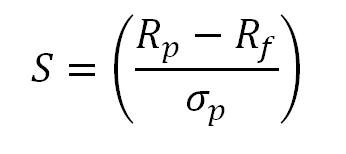

Rp = return of stock (or portfolio)

Rf = Risk-Free Rate

𝝈𝒑 = Standard deviation of stock (or portfolio)



In [72]:
Sharpe = (Apple_ER - rfr_today) / (simple_returns['AAPL'].std() * 250 ** 0.5)
Sharpe #both the time and the variance need a square root to obtain the STD
#this ratio is for comparing different stocks in stock portfolios

np.float64(0.284107984674713)

## Alpha


Shows us the amount of return we are getting without extra risk